# ZTF (DAOPhot reference catalogs) vs Pan-STARRS, quadrant 643_11_1

Inputs come from the merge and match run on 2026-11-11: three ZTF `refpsfcat` catalogs merged into objects (mutual nearest neighbour at 1"), then matched to PS1 objects the same way. Tables live in `Data/ztf_data/`.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

obj = pd.read_parquet('../Data/ztf_data/ztfobj_643_11_1.parquet')   # one row per ZTF object; {band}_mag etc.; ps1_idx, ps1_sep
ps1 = pd.read_parquet('../Data/ztf_data/ps1_643_11_1.parquet')      # PS1 objects on valid ZTF pixels; ps1_idx indexes this
matched = obj[obj.ps1_idx >= 0].copy()
for b in 'gri':
    matched[f'ps1_{b}_psf'] = ps1[f'{b}PSFMag'].values[matched.ps1_idx]
    matched[f'ps1_{b}_kron'] = ps1[f'{b}KronMag'].values[matched.ps1_idx]
print(len(obj), 'ZTF objects;', len(matched), 'matched to PS1')

99791 ZTF objects; 51301 matched to PS1


## 1. Angular separations

Left: ZTF object to its PS1 match. Right: each band's source to the merged ZTF object position (how well the three ZTF references agree with each other).

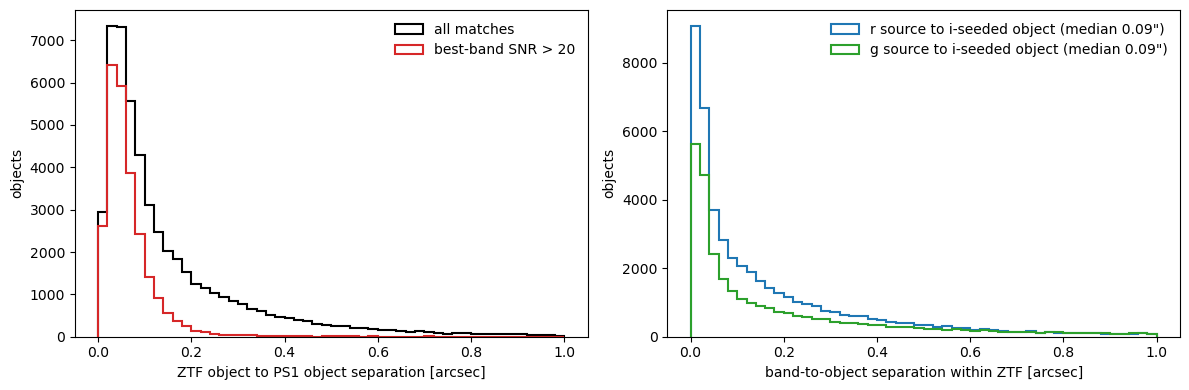

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 51)
axes[0].hist(matched.ps1_sep, bins=bins, histtype='step', lw=1.5, color='k', label='all matches')
bright = matched[matched[['g_snr', 'r_snr', 'i_snr']].max(axis=1) > 20]
axes[0].hist(bright.ps1_sep, bins=bins, histtype='step', lw=1.5, color='C3', label='best-band SNR > 20')
axes[0].set_xlabel('ZTF object to PS1 object separation [arcsec]')
axes[0].set_ylabel('objects')
axes[0].legend(frameon=False)
for b, c in zip('rg', ['C0', 'C2']):
    s = obj[f'{b}_sep'].dropna()
    axes[1].hist(s, bins=bins, histtype='step', lw=1.5, color=c, label=f'{b} source to i-seeded object (median {s.median():.2f}")')
axes[1].set_xlabel('band-to-object separation within ZTF [arcsec]')
axes[1].set_ylabel('objects')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. PS1 PSF vs ZTF PSF magnitude per band

Point sources (|PS1 PSF − Kron| < 0.05) in black, everything else in colour. The dashed line is equality; the lower row is the residual.

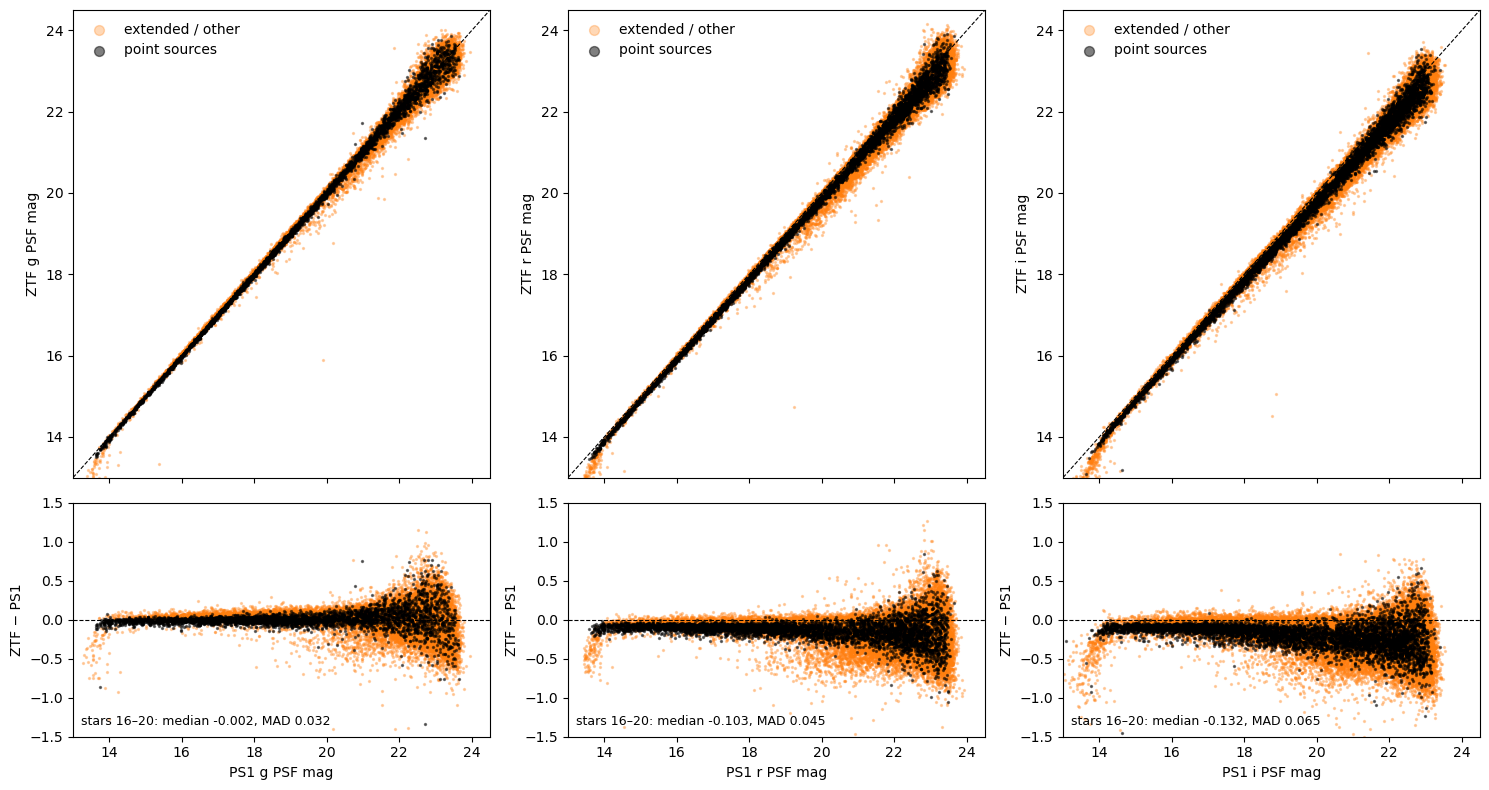

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex='col', gridspec_kw={'height_ratios': [2, 1]})
for j, b in enumerate('gri'):
    m = matched[matched[f'{b}_idx'] >= 0]
    x, y = m[f'ps1_{b}_psf'], m[f'{b}_mag']
    star = (m[f'ps1_{b}_psf'] - m[f'ps1_{b}_kron']).abs() < 0.05
    ax = axes[0, j]
    ax.scatter(x[~star], y[~star], s=2, alpha=0.3, color='C1', label='extended / other')
    ax.scatter(x[star], y[star], s=2, alpha=0.5, color='k', label='point sources')
    lim = (13, 24.5)
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_ylabel(f'ZTF {b} PSF mag')
    ax.legend(frameon=False, loc='upper left', markerscale=5)
    ax = axes[1, j]
    d = y - x
    ax.scatter(x[~star], d[~star], s=2, alpha=0.3, color='C1')
    ax.scatter(x[star], d[star], s=2, alpha=0.5, color='k')
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel(f'PS1 {b} PSF mag')
    ax.set_ylabel('ZTF − PS1')
    sel = star & (x > 16) & (x < 20)
    ax.text(0.02, 0.05, f'stars 16–20: median {d[sel].median():+.3f}, MAD {1.4826*np.median(np.abs(d[sel]-d[sel].median())):.3f}', transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

## 3. Unmatched examples, before any filtering

Rows are objects with no counterpart: first the brightest ZTF-only objects detected in at least two bands, then the brightest PS1-only objects. Left is the ZTF r reference, right the PS1 r stack (from the local skycells), both 30" on a side, north up and east left, log stretch at the 99.5th percentile. Markers are merged ZTF objects and PS1 objects coloured by match status; the cross is the object in question.

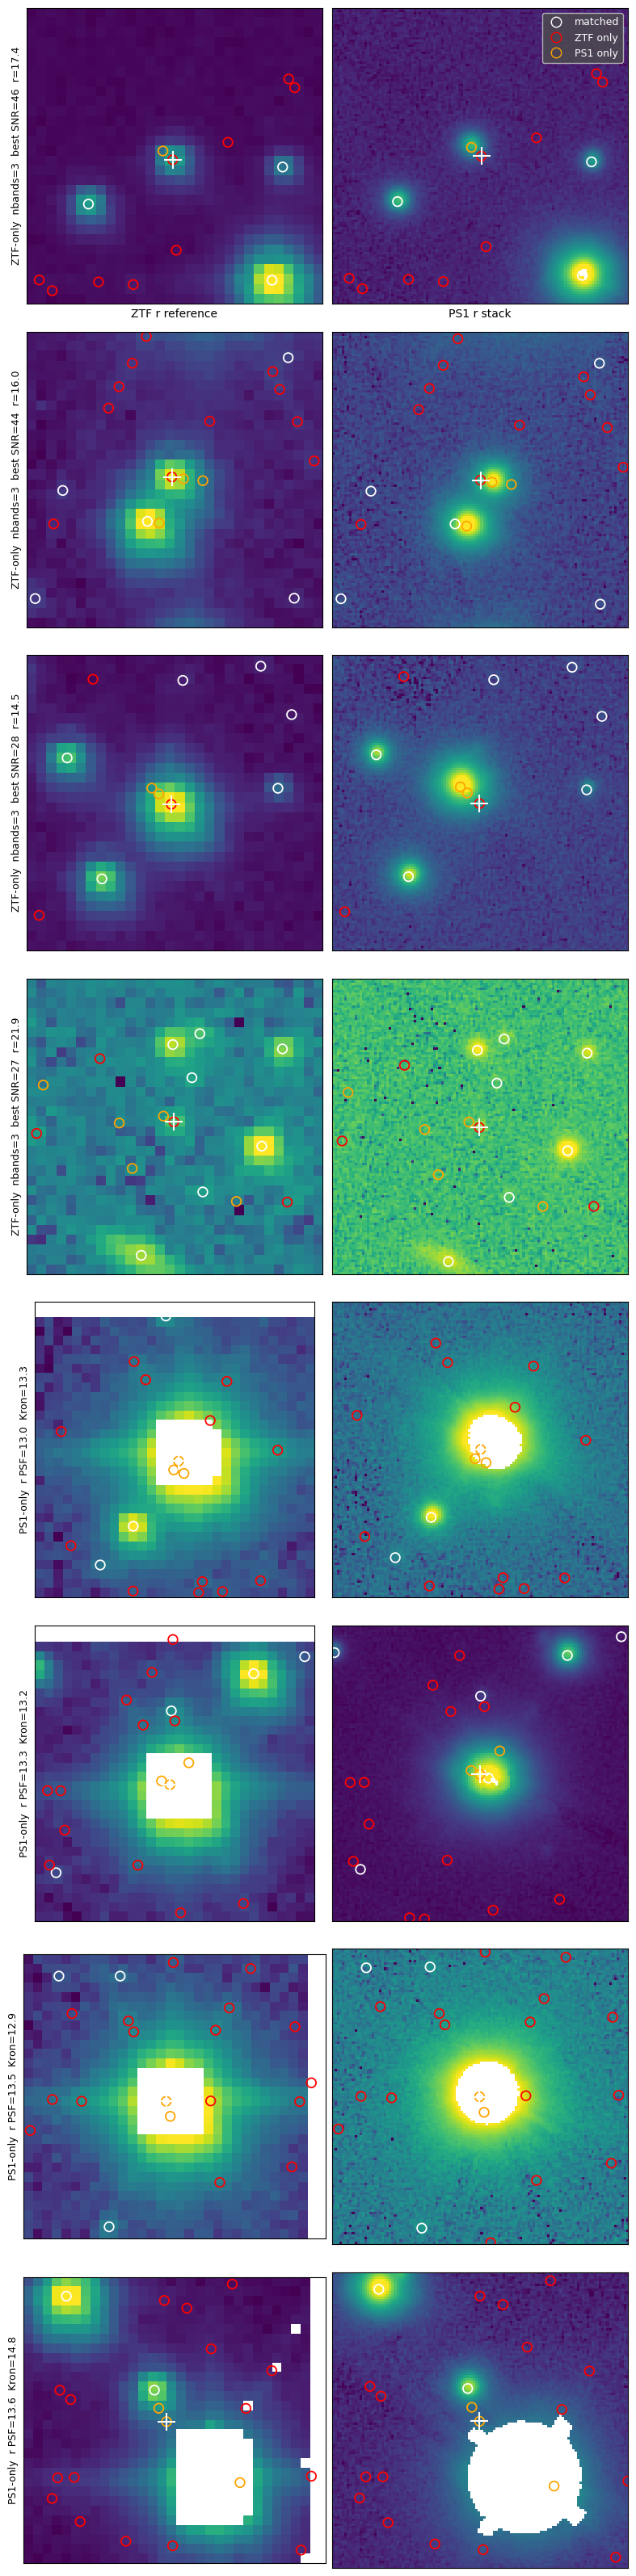

In [11]:
import glob, os, sys
sys.path.insert(0, '..')
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy.visualization import simple_norm
from matplotlib.lines import Line2D
import astropy.units as u
from Extracting.images import load_ztf_refimg, load_ps1_skycell
from Extracting.ztf_images import refimg_path

D = '../Data'
ztf_img = load_ztf_refimg(refimg_path(f'{D}/ztf_data', 643, 11, 1, 'r'))
ps1_only_mask = ~np.isin(np.arange(len(ps1)), obj.ps1_idx[obj.ps1_idx >= 0])
classes = {   # label: (ra, dec, colour)
    'matched': (obj.ra[obj.ps1_idx >= 0].values, obj.dec[obj.ps1_idx >= 0].values, 'white'),
    'ZTF only': (obj.ra[obj.ps1_idx < 0].values, obj.dec[obj.ps1_idx < 0].values, 'red'),
    'PS1 only': (ps1.ra[ps1_only_mask].values, ps1.dec[ps1_only_mask].values, 'orange'),
}
ps1_imgs = {}   # loaded on demand, keyed by skycell name
def ps1_image_at(ra, dec):
    for stack in sorted(glob.glob(f'{D}/ps1_data/rings.v3.skycell.*.stk.r.unconv.fits')):
        name = os.path.basename(stack).split('.stk.')[0]
        if name not in ps1_imgs:
            ps1_imgs[name] = load_ps1_skycell(stack, stack.replace('.fits', '.mask.fits'))
        im = ps1_imgs[name]
        x, y = im.wcs.world_to_pixel_values(ra, dec)
        if 70 < x < im.shape[1] - 70 and 70 < y < im.shape[0] - 70:
            return im
    return None

def north_up_east_left(cut):
    """Flip a cutout so RA increases to the left and Dec upward; also returns a pixel-coordinate mapper.
    ZTF references are stored north-down/east-right, PS1 skycells north-up/east-left; the residual
    rotation between them is ~0.2 deg, so axis flips are enough to display them the same way."""
    cd = cut.wcs.pixel_scale_matrix
    flip_x, flip_y = cd[0, 0] > 0, cd[1, 1] < 0
    data = cut.data[:, ::-1] if flip_x else cut.data
    data = data[::-1, :] if flip_y else data
    ny, nx = cut.shape
    def to_display(x, y):
        return (nx - 1 - x if flip_x else x), (ny - 1 - y if flip_y else y)
    return data, to_display

def show(ax, im, ra, dec, size_arcsec=30):
    cut = Cutout2D(im.data, SkyCoord(ra * u.deg, dec * u.deg), size_arcsec * u.arcsec, wcs=im.wcs)
    data, to_display = north_up_east_left(cut)
    ax.imshow(data, origin='lower', cmap='viridis', norm=simple_norm(data, 'log', percent=99.5))
    for label, (cra, cdec, colour) in classes.items():
        x, y = to_display(*cut.wcs.world_to_pixel_values(cra, cdec))
        s = (x > 0) & (x < cut.shape[1]) & (y > 0) & (y < cut.shape[0])
        ax.scatter(x[s], y[s], s=70, facecolors='none', edgecolors=colour, lw=1.3)
    x0, y0 = to_display(*cut.wcs.world_to_pixel_values(ra, dec))
    ax.plot(x0, y0, '+', color='white', ms=16, mew=1.5)
    ax.set_xticks([]); ax.set_yticks([])

ztf_only = obj[(obj.ps1_idx < 0) & (obj.nbands >= 2)].sort_values('best_snr', ascending=False).head(4)
ps1_only = ps1[ps1_only_mask & (ps1.rPSFMag > 0)].sort_values('rPSFMag').head(4)
rows = [(r.ra, r.dec, f'ZTF-only  nbands={r.nbands}  best SNR={r.best_snr:.0f}  r={r.r_mag:.1f}') for r in ztf_only.itertuples()] +        [(r.ra, r.dec, f'PS1-only  r PSF={r.rPSFMag:.1f}  Kron={r.rKronMag:.1f}') for r in ps1_only.itertuples()]
fig, axes = plt.subplots(len(rows), 2, figsize=(8, 4 * len(rows)))
for (ra, dec, label), (axl, axr) in zip(rows, axes):
    show(axl, ztf_img, ra, dec)
    axl.set_ylabel(label, fontsize=9)
    pim = ps1_image_at(ra, dec)
    if pim is not None:
        show(axr, pim, ra, dec)
    else:
        axr.set_axis_off()
axes[0, 0].set_xlabel('ZTF r reference'); axes[0, 1].set_xlabel('PS1 r stack')
handles = [Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor=c, markersize=9, label=l) for l, (_, _, c) in classes.items()]
axes[0, 1].legend(handles=handles, loc='upper right', frameon=True, facecolor='0.3', labelcolor='white', fontsize=9)
plt.tight_layout()
plt.show()

## 4. Filtering the PS1-only objects

Cumulative cuts, with the number of objects surviving each. Bit values are from the archive's flag pages.

- **Near masked ZTF pixels**: within 5 px of a NaN in any ZTF band (saturated cores, defects and the coverage border are NaN in the references). Same test and radius as the original association step.
- **Saturation**: `infoFlag` SATSTAR (128) or SATURATED (4096), or `infoFlag2` SATSTAR_PROFILE (4096), in any measured band.
- **PS1 artefact**: `infoFlag2` ON_SPIKE (8), ON_STARCORE (16), ON_BURNTOOL (32) or ON_CONVPOOR (64): more than a quarter of the PSF-weighted pixels on a spike, a bright-star core, a streak or a poorly convolved region. Catches spurious entries inside saturated PS1 cores that carry no saturation bit.
- **Stack quality**: `qualityFlag` BAD_STACK (128), at most one good or suspect stack measurement.
- **Signal-to-noise**: PSF SNR = 1.0857 / PSFMagErr, at least 5 in one band; the two-band line is shown for reference.

In [12]:
import sys
sys.path.insert(0, '..')
from scipy.ndimage import distance_transform_edt
from Extracting.images import load_ztf_refimg
from Extracting.ztf_images import refimg_path
D = '../Data'

# Distance (px) from every pixel to the nearest masked (NaN) pixel, per ZTF band. Saturated cores,
# defects and the no-coverage border are all NaN in the references, so one test covers them.
ztf_imgs = {b: load_ztf_refimg(refimg_path(f'{D}/ztf_data', 643, 11, 1, b)) for b in 'gri'}
nan_dist = {b: distance_transform_edt(~im.bad) for b, im in ztf_imgs.items()}

def min_nan_distance(ra, dec, bands='gri'):
    """Smallest distance to a masked ZTF pixel over the given bands, in pixels; inf if outside every image."""
    out = np.full(len(ra), np.inf)
    for b in bands:
        im = ztf_imgs[b]
        x, y = im.wcs.world_to_pixel_values(ra, dec)
        inside = (x >= 0) & (x < im.shape[1]) & (y >= 0) & (y < im.shape[0])
        xi, yi = np.clip(x.round().astype(int), 0, im.shape[1] - 1), np.clip(y.round().astype(int), 0, im.shape[0] - 1)
        out = np.where(inside, np.minimum(out, nan_dist[b][yi, xi]), out)
    return out

def has_bit(col, bit):
    return (col.fillna(0).astype('int64') & bit) != 0

def waterfall(steps, extra=None, extra_label=''):
    """Print objects surviving each cumulative step; `extra` is a boolean mask for a second column."""
    print(f'{"step":46s} {"objects":>8s} {extra_label:>10s}')
    for label, m in steps:
        print(f'{label:46s} {m.sum():8d} {(m & extra).sum() if extra is not None else "":>10}')

step                                            objects       r<19
all PS1-only                                       7410        101
not within 5 px of a masked ZTF pixel              6597         53
not saturated (PS1 flags)                          6438         24
not on a PS1 artefact (spike / star core / streak)     6405         22
not BAD_STACK                                      1112         16
SNR >= 5 in >= 1 band                              1083         16
SNR >= 5 in >= 2 bands                              282         14


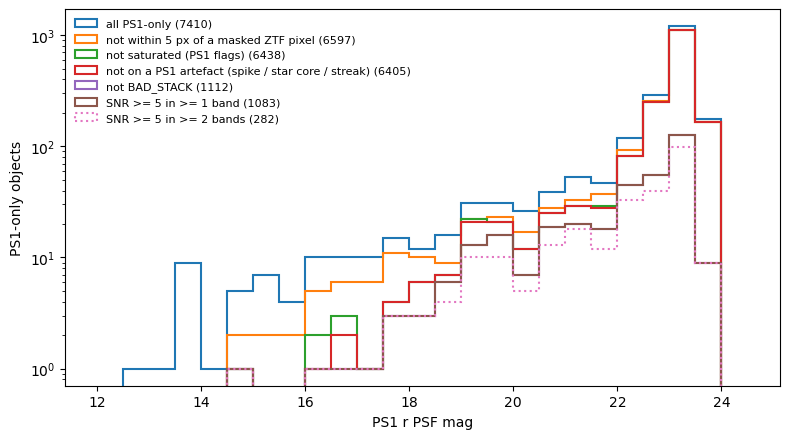

In [13]:
SATSTAR, SATURATED, SATSTAR_PROFILE = 128, 4096, 4096          # infoFlag / infoFlag2
ON_SPIKE, ON_STARCORE, ON_BURNTOOL, ON_CONVPOOR = 8, 16, 32, 64   # infoFlag2
BAD_STACK, SUSPECT_STACK, GOOD_STACK = 128, 64, 16                # qualityFlag
NAN_RADIUS_PS1_PX = 5     # as in the original association step
SNR_MIN = 5.0

ps1_only_mask = ~np.isin(np.arange(len(ps1)), obj.ps1_idx[obj.ps1_idx >= 0])
ps1_only = ps1[ps1_only_mask].copy()

near_nan = min_nan_distance(ps1_only.ra.values, ps1_only.dec.values) <= NAN_RADIUS_PS1_PX
saturated = np.zeros(len(ps1_only), bool); artefact = np.zeros(len(ps1_only), bool)
for b in 'gri':
    measured = ps1_only[f'{b}PSFMag'].notna()
    saturated |= measured & (has_bit(ps1_only[f'{b}infoFlag'], SATSTAR) | has_bit(ps1_only[f'{b}infoFlag'], SATURATED) | has_bit(ps1_only[f'{b}infoFlag2'], SATSTAR_PROFILE))
    for bit in (ON_SPIKE, ON_STARCORE, ON_BURNTOOL, ON_CONVPOOR):
        artefact |= measured & has_bit(ps1_only[f'{b}infoFlag2'], bit)
bad_stack = has_bit(ps1_only.qualityFlag, BAD_STACK)
ps1_snr = pd.DataFrame({b: 1.0857 / ps1_only[f'{b}PSFMagErr'] for b in 'gri'})
n_snr_bands = (ps1_snr >= SNR_MIN).sum(axis=1)

ok = np.ones(len(ps1_only), bool); ps1_steps = [('all PS1-only', ok.copy())]
for label, cut in [(f'not within {NAN_RADIUS_PS1_PX} px of a masked ZTF pixel', ~near_nan),
                   ('not saturated (PS1 flags)', ~saturated),
                   ('not on a PS1 artefact (spike / star core / streak)', ~artefact),
                   ('not BAD_STACK', ~bad_stack),
                   (f'SNR >= {SNR_MIN:.0f} in >= 1 band', (n_snr_bands >= 1).values),
                   (f'SNR >= {SNR_MIN:.0f} in >= 2 bands', (n_snr_bands >= 2).values)]:
    ok = ok & cut; ps1_steps.append((label, ok.copy()))
waterfall(ps1_steps, extra=(ps1_only.rPSFMag < 19).values, extra_label='r<19')
ps1_only_clean = ps1_only[ps1_steps[-2][1]]       # keep the >= 1-band set; the 2-band line is shown for reference

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(12, 25, 0.5)
for k, (label, m) in enumerate(ps1_steps):
    ax.hist(ps1_only.rPSFMag[m].dropna(), bins=bins, histtype='step', lw=1.5, label=f'{label} ({m.sum()})', color=f'C{k}', ls='-' if k < len(ps1_steps) - 1 else ':')
ax.set_xlabel('PS1 r PSF mag'); ax.set_ylabel('PS1-only objects'); ax.set_yscale('log'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Are the PS1-only survivors blend components?

Distance from each survivor to the nearest other PS1 object, and whether that neighbour is the one ZTF matched. A survivor whose neighbour was matched to ZTF is a PS1-resolved component of a source ZTF saw as one peak.

  radius  has neighbour  neighbour matched  neighbour brighter  r<19 with neighbour
    1.0"       36 (  3%)                 30                   4            2 / 16
    1.5"      122 ( 11%)                104                  17            5 / 16
    2.0"      211 ( 19%)                180                  25            7 / 16
    3.0"      459 ( 42%)                414                  74           14 / 16
    5.0"      821 ( 76%)                733                 124           15 / 16

no other PS1 object within 3": 624; r PSF pct 10/50/90 = [20.8 23.1 23.4]; with 2 bands at SNR >= 5: 168


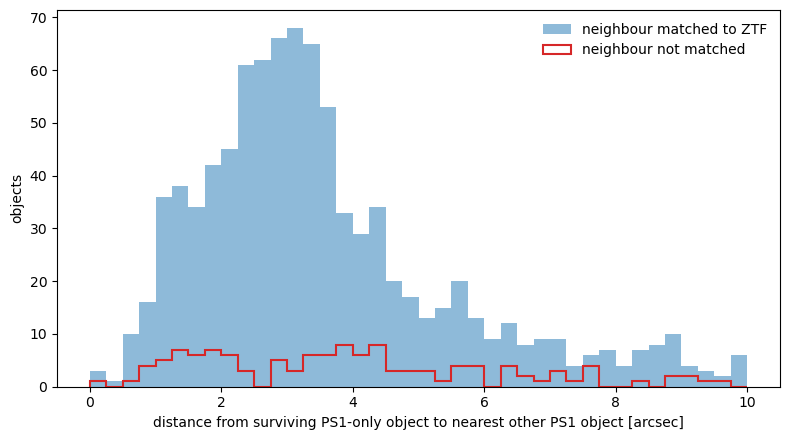

In [14]:
from scipy.spatial import cKDTree
cosd = np.cos(np.radians(ps1.dec.median()))
surv = ps1_only_clean
d, i = cKDTree(np.c_[ps1.ra.values * cosd, ps1.dec.values]).query(np.c_[surv.ra.values * cosd, surv.dec.values], k=2)
d_other, j_other = d[:, 1] * 3600, i[:, 1]                      # k=1 is the object itself
matched_mask = np.isin(np.arange(len(ps1)), obj.ps1_idx[obj.ps1_idx >= 0])
neighbour_matched = matched_mask[j_other]
neighbour_brighter = ps1.rPSFMag.values[j_other] < surv.rPSFMag.values
bright_r = (surv.rPSFMag < 19).values
two_bands = (n_snr_bands >= 2).values[ps1_steps[-2][1]]

print(f'{"radius":>8s} {"has neighbour":>14s} {"neighbour matched":>18s} {"neighbour brighter":>19s} {"r<19 with neighbour":>20s}')
for r in (1.0, 1.5, 2.0, 3.0, 5.0):
    near = d_other < r
    print(f'{r:7.1f}" {near.sum():8d} ({100*near.mean():3.0f}%) {(near & neighbour_matched).sum():18d} {(near & neighbour_brighter).sum():19d} {(near & bright_r).sum():12d} / {bright_r.sum()}')
far = d_other >= 3.0
print(f'\nno other PS1 object within 3": {far.sum()}; r PSF pct 10/50/90 = {np.round(np.nanpercentile(surv.rPSFMag[far], [10, 50, 90]), 1)}; with 2 bands at SNR >= {SNR_MIN:.0f}: {(far & two_bands).sum()}')

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, 10.25, 0.25)
ax.hist(d_other[neighbour_matched], bins=bins, histtype='stepfilled', alpha=0.5, color='C0', label='neighbour matched to ZTF')
ax.hist(d_other[~neighbour_matched], bins=bins, histtype='step', lw=1.5, color='C3', label='neighbour not matched')
ax.set_xlabel('distance from surviving PS1-only object to nearest other PS1 object [arcsec]')
ax.set_ylabel('objects'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Filtering the ZTF-only objects

Same layout, with each PS1-side cut given its ZTF-side counterpart.

- **Near masked ZTF pixels**: within 15 px of a NaN, the radius the original association used for ZTF sources. Removes bright-star halos and spikes, since the star's core is NaN.
- **Saturation**: ZTF PSF magnitude brighter than 13.5 in any detected band, the ZTF clause of `pstarr_not_saturated`.
- **Near a bright star**: within 10" of a PS1 star brighter than r = 14, growing by 5" per magnitude above that. The ZTF counterpart of PS1's ON_STARCORE / ON_SPIKE flags, for halo and spike detections that are not close enough to the NaN core to be caught above.
- **Coverage**: at least half the median number of input frames at the position in every detected band (`refcov`), the counterpart of BAD_STACK.
- **DAOPhot flags**: zero in every detected band.
- **Signal-to-noise**: DAOPhot SNR at least 5 in one band, then in two bands. Single-band ZTF-only objects are the detection limit of one reference and are dropped by the last step.

step                                            objects bestSNR>10
all ZTF-only                                      48490        862
not within 15 px of a masked ZTF pixel            42474        658
DAOPhot flags == 0 in every detected band         42474        658
|sharp| <= 0.5 in every detected band (provisional)    40067        649
chi <= 3.0 in every detected band (provisional)    39903        638
SNR >= 5 in >= 1 band                             10971        638
SNR >= 5 in >= 2 bands                             1543        271


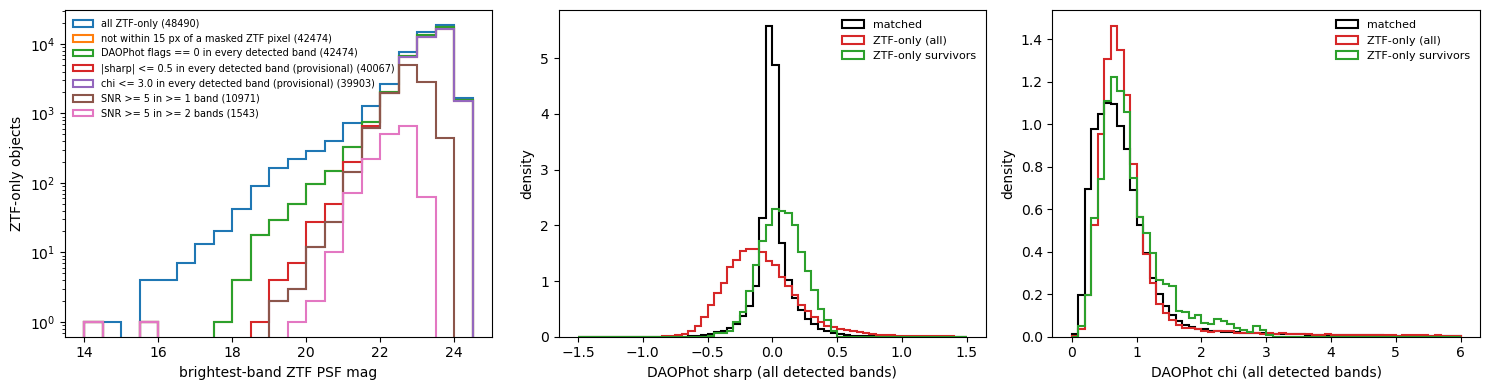

In [15]:
NAN_RADIUS_ZTF_PX = 15    # the original association used 15 px for ZTF sources
ZTF_SAT_MAG = 13.5        # pstarr_not_saturated's ZTF clause
BRIGHT_STAR_MAG, BRIGHT_STAR_RADIUS, BRIGHT_STAR_SLOPE = 14.0, 10.0, 5.0   # arcsec at r=14, +5" per mag brighter
MIN_COVERAGE_FRAC = 0.5

from astropy.io import fits
ztf_only = obj[obj.ps1_idx < 0].copy()
near_nan_z = min_nan_distance(ztf_only.ra.values, ztf_only.dec.values) <= NAN_RADIUS_ZTF_PX
saturated_z = np.zeros(len(ztf_only), bool); flagged = np.zeros(len(ztf_only), bool); low_cov = np.zeros(len(ztf_only), bool)
for b in 'gri':
    det = (ztf_only[f'{b}_idx'] >= 0).values
    saturated_z |= det & (ztf_only[f'{b}_mag'].values < ZTF_SAT_MAG)
    src_b = pd.read_parquet(f'{D}/ztf_data/ztfpsf_643_11_1_{b}.parquet')
    flagged |= det & (src_b['flags'].values[ztf_only[f'{b}_idx'].clip(lower=0).values] != 0)
    cov = fits.open(refimg_path(f'{D}/ztf_data', 643, 11, 1, b, 'refcov'))[0].data
    im = ztf_imgs[b]; x, y = im.wcs.world_to_pixel_values(ztf_only.ra.values, ztf_only.dec.values)
    xi, yi = np.clip(x.round().astype(int), 0, im.shape[1] - 1), np.clip(y.round().astype(int), 0, im.shape[0] - 1)
    low_cov |= det & (cov[yi, xi] < MIN_COVERAGE_FRAC * np.nanmedian(cov))
bright = ps1[ps1.rPSFMag < BRIGHT_STAR_MAG]
d_star, i_star = cKDTree(np.c_[bright.ra.values * cosd, bright.dec.values]).query(np.c_[ztf_only.ra.values * cosd, ztf_only.dec.values])
near_bright = d_star * 3600 < BRIGHT_STAR_RADIUS + BRIGHT_STAR_SLOPE * (BRIGHT_STAR_MAG - bright.rPSFMag.values[i_star])
n_snr_bands_z = sum(((ztf_only[f'{b}_snr'] >= SNR_MIN).fillna(False)).astype(int) for b in 'gri')

ok = np.ones(len(ztf_only), bool); ztf_steps = [('all ZTF-only', ok.copy())]
for label, cut in [(f'not within {NAN_RADIUS_ZTF_PX} px of a masked ZTF pixel', ~near_nan_z),
                   (f'not saturated (ZTF PSF mag > {ZTF_SAT_MAG})', ~saturated_z),
                   (f'not near a bright star (r < {BRIGHT_STAR_MAG:.0f})', ~near_bright),
                   (f'coverage >= {MIN_COVERAGE_FRAC:.0%} of median in every detected band', ~low_cov),
                   ('DAOPhot flags == 0 in every detected band', ~flagged),
                   (f'SNR >= {SNR_MIN:.0f} in >= 1 band', (n_snr_bands_z >= 1).values),
                   (f'SNR >= {SNR_MIN:.0f} in >= 2 bands', (n_snr_bands_z >= 2).values)]:
    ok = ok & cut; ztf_steps.append((label, ok.copy()))
waterfall(ztf_steps, extra=(ztf_only.best_snr > 10).values, extra_label='bestSNR>10')
ztf_only_clean = ztf_only[ztf_steps[-1][1]]        # keep the 2-band set

fig, ax = plt.subplots(figsize=(8, 4.5))
best = ztf_only[['g_mag', 'r_mag', 'i_mag']].min(axis=1)
bins = np.arange(14, 25, 0.5)
for k, (label, m) in enumerate(ztf_steps):
    ax.hist(best[m].dropna(), bins=bins, histtype='step', lw=1.5, color=f'C{k}', label=f'{label} ({m.sum()})', ls='-' if k < len(ztf_steps) - 1 else ':')
ax.set_xlabel('brightest-band ZTF PSF mag'); ax.set_ylabel('ZTF-only objects'); ax.set_yscale('log'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 6. Unmatched examples, after filtering

Same layout as section 3. First the PS1-only survivors, then the ZTF-only survivors; in each case the four brightest followed by four at random.

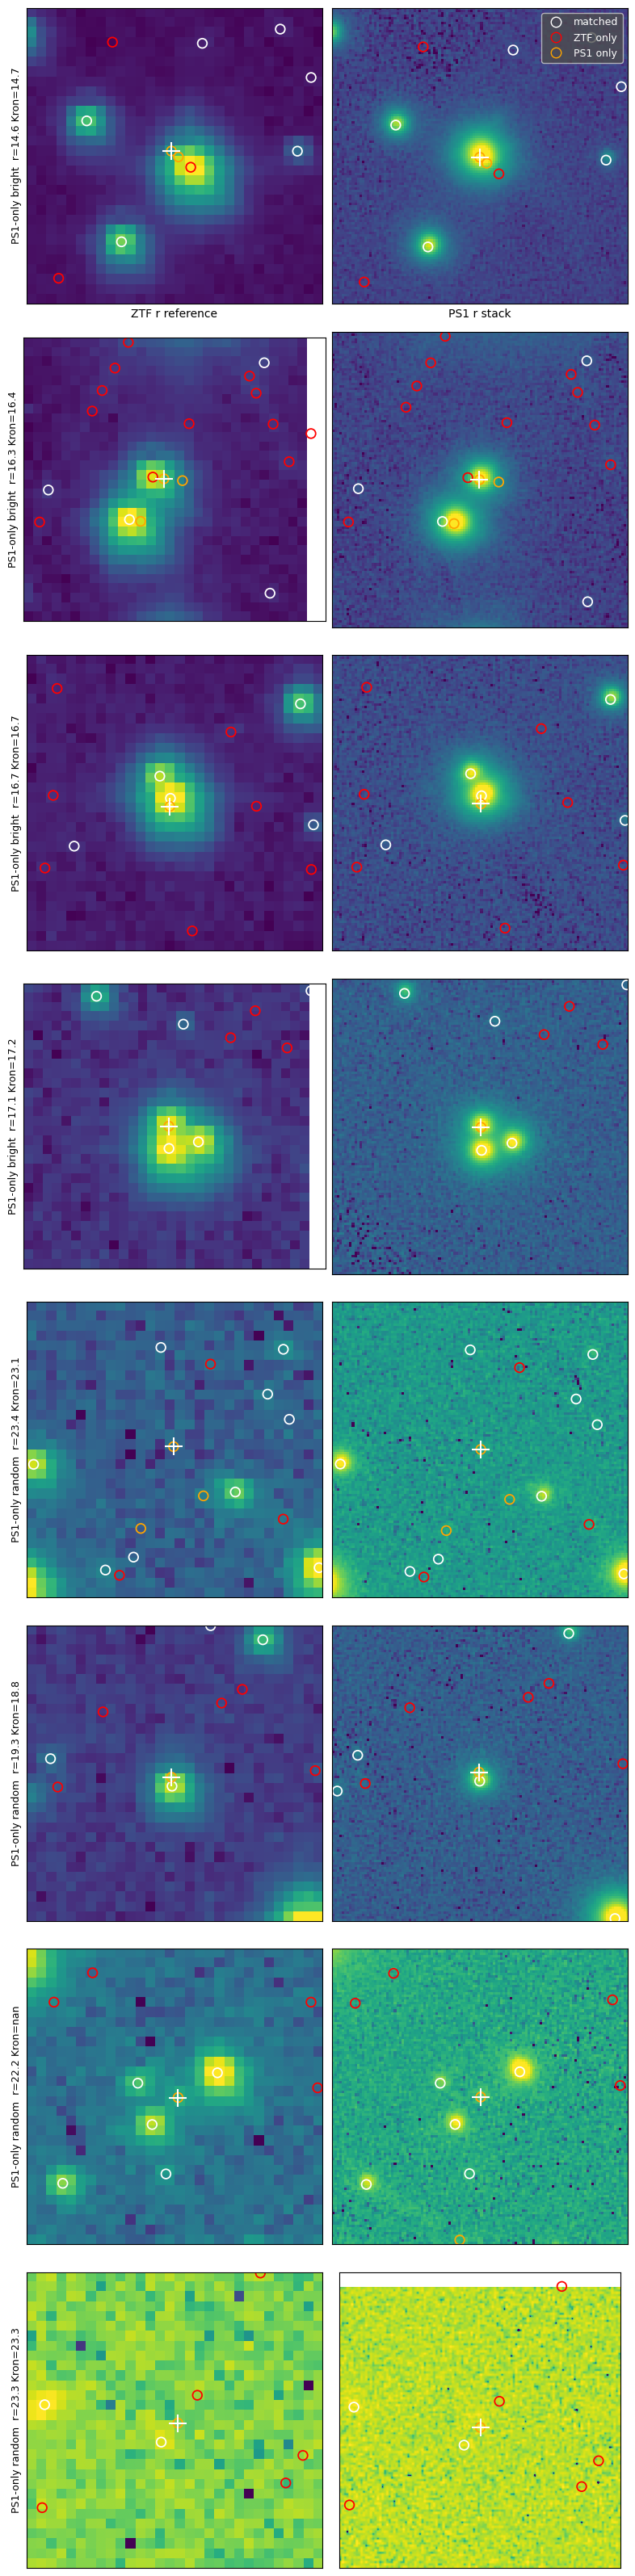

In [16]:
def cutout_grid(rows, title_left='ZTF r reference', title_right='PS1 r stack'):
    fig, axes = plt.subplots(len(rows), 2, figsize=(8, 4 * len(rows)))
    for (ra, dec, label), (axl, axr) in zip(rows, axes):
        show(axl, ztf_img, ra, dec); axl.set_ylabel(label, fontsize=9)
        pim = ps1_image_at(ra, dec)
        show(axr, pim, ra, dec) if pim is not None else axr.set_axis_off()
    axes[0, 0].set_xlabel(title_left); axes[0, 1].set_xlabel(title_right)
    axes[0, 1].legend(handles=handles, loc='upper right', frameon=True, facecolor='0.3', labelcolor='white', fontsize=9)
    plt.tight_layout(); plt.show()

# PS1-only survivors: the four brightest, then four at random
surv = ps1_only_clean[ps1_only_clean.rPSFMag.notna()]
brightest = surv.sort_values('rPSFMag').head(4); rest = surv.drop(brightest.index).sample(min(4, len(surv) - 4), random_state=0)
cutout_grid([(r.ra, r.dec, f'PS1-only bright  r={r.rPSFMag:.1f} Kron={r.rKronMag:.1f}') for r in brightest.itertuples()] +
            [(r.ra, r.dec, f'PS1-only random  r={r.rPSFMag:.1f} Kron={r.rKronMag:.1f}') for r in rest.itertuples()])

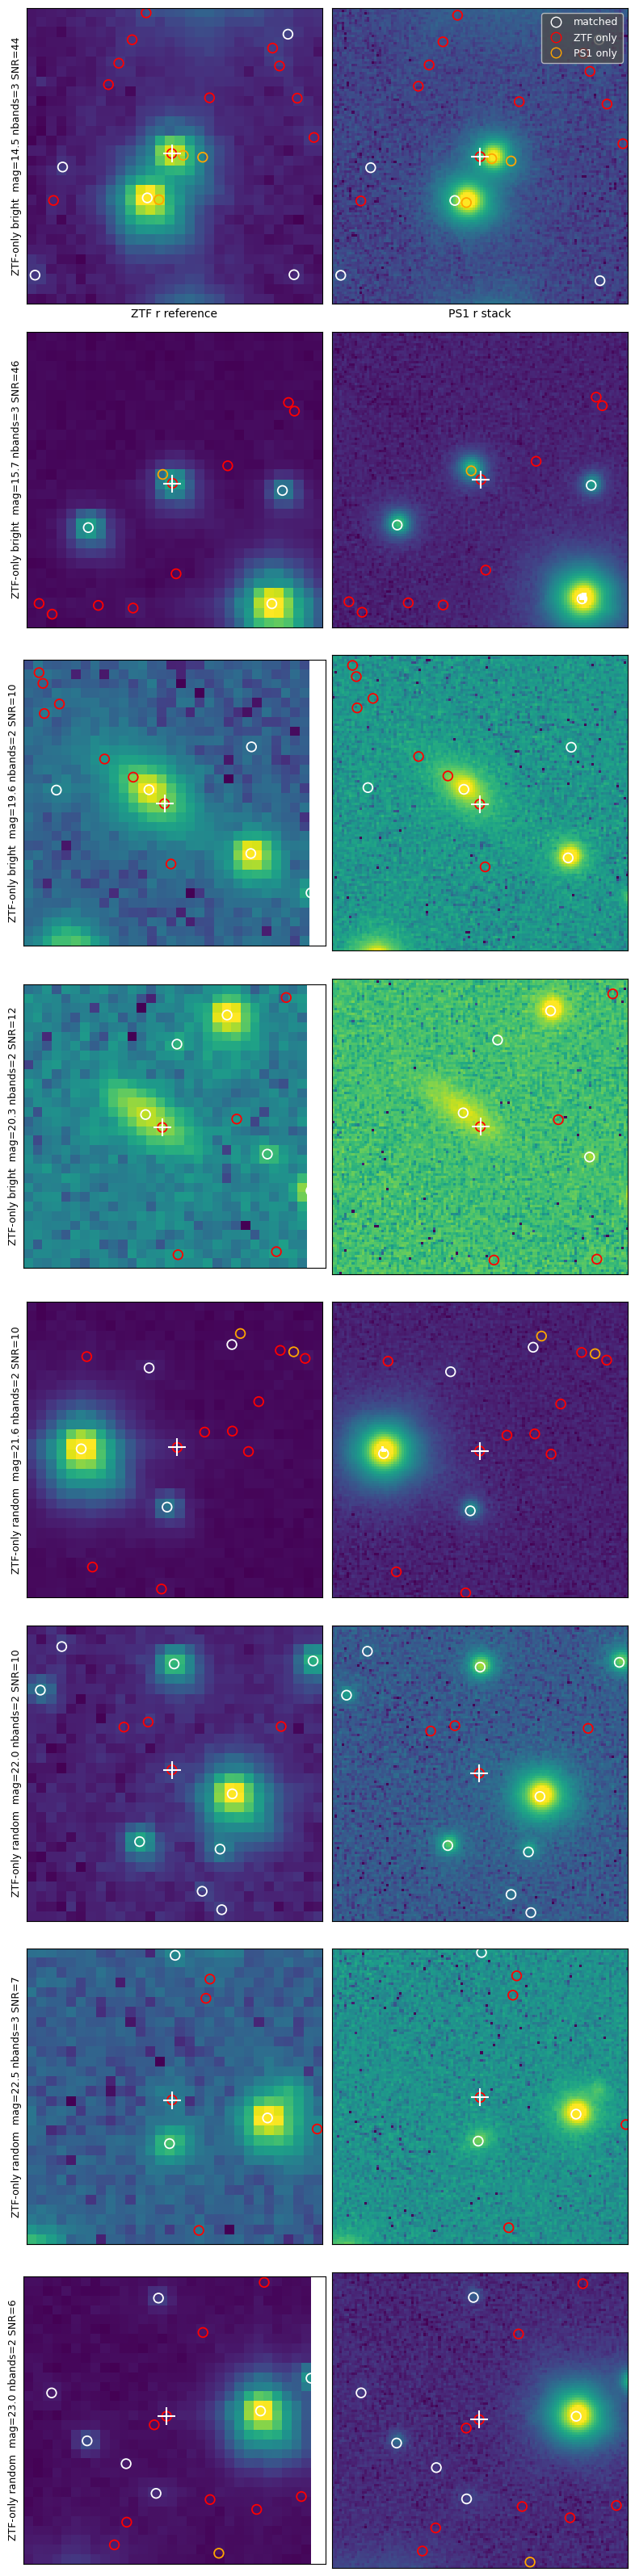

In [17]:
# ZTF-only survivors: the four brightest, then four at random
surv = ztf_only_clean.copy(); surv['best_mag'] = surv[['g_mag', 'r_mag', 'i_mag']].min(axis=1)
brightest = surv.sort_values('best_mag').head(4); rest = surv.drop(brightest.index).sample(min(4, len(surv) - 4), random_state=0)
cutout_grid([(r.ra, r.dec, f'ZTF-only bright  mag={r.best_mag:.1f} nbands={r.nbands} SNR={r.best_snr:.0f}') for r in brightest.itertuples()] +
            [(r.ra, r.dec, f'ZTF-only random  mag={r.best_mag:.1f} nbands={r.nbands} SNR={r.best_snr:.0f}') for r in rest.itertuples()])